## ใช้ข้อมูลใดและจากแหล่งใด

งานนี้ใช้ข้อมูล **NYC TLC Trip Record Data** จาก [New York City Taxi & Limousine Commission (NYC TLC)](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) โดยศึกษาข้อมูลการเดินทางของ Taxi 4 ประเภท ได้แก่ Yellow, Green, FHV และ High Volume FHV ในช่วงเดือนมกราคมถึงมิถุนายน 2024

ข้อมูลที่นำมาใช้มีทั้งหมด 24 ไฟล์ คิดจาก 4 ประเภท * 6 เดือน โดยแต่ละไฟล์อยู่ในรูปแบบ Parquet และเผยแพร่แยกตามประเภท Taxi และเดือน สำหรับ URL ของแต่ละไฟล์จะถูกบันทึกไว้ใน Manifest เพื่อให้สามารถตรวจสอบย้อนกลับไปยังแหล่งข้อมูลต้นทางได้

## เตรียม ตรวจสอบ ทำความสะอาด แปลง และจัดเก็บข้อมูลอย่างไร

- **การเตรียมข้อมูล:** กำหนดช่วงเวลาที่ใช้ในการศึกษา ประเภท Taxi ทั้ง 4 ประเภท ชื่อคอลัมน์ที่จำเป็น และตรวจสอบพื้นที่ว่างของ Google Colab ก่อนเริ่มประมวลผล
- **การนำเข้าและจัดเก็บข้อมูล:** ดาวน์โหลดไฟล์ตามรายการใน Manifest และจัดเก็บไว้ชั่วคราวใน content/nyc_taxi_data หากมีไฟล์เดิมอยู่แล้วจะนำกลับมาใช้โดยไม่ดาวน์โหลดซ้ำ ส่วนระหว่างการดาวน์โหลดจะใช้ไฟล์นามสกุล .part เพื่อป้องกันไม่ให้ไฟล์ที่ยังดาวน์โหลดไม่สมบูรณ์ถูกนำไปใช้งานต่อ
- **การตรวจสอบข้อมูล:** ตรวจสอบว่า Manifest มีครบ 24 รายการ ไม่มีคู่ประเภท Taxi และเดือนซ้ำกัน ไฟล์ทุกไฟล์สามารถเปิดอ่านได้ มีข้อมูล และมีคอลัมน์ Pickup และ Dropoff ตรงตาม Schema ที่กำหนดไว้
- **การทำความสะอาดข้อมูล:** กำหนดให้ข้อมูลที่ผ่านการตรวจสอบต้องมีค่า Pickup และ Dropoff ครบถ้วน เวลา Pickup อยู่ในช่วงที่ศึกษา และเวลา Dropoff ต้องไม่เกิดก่อน Pickup ส่วนข้อมูลที่น่าสงสัย เช่น ระยะทางเป็นศูนย์ ค่าโดยสารติดลบ จำนวนผู้โดยสารที่หายไป และข้อมูลที่อาจซ้ำกัน จะใช้เป็นข้อมูลประกอบการตรวจสอบเท่านั้น โดยยังไม่นำมาใช้เป็นเงื่อนไขในการตัดข้อมูลออก
- **การแปลงข้อมูล:** นำผลการตรวจสอบของแต่ละไฟล์มาแปลงให้อยู่ในรูปแบบ Audit Table เดียวกัน โดยเก็บจำนวน raw, valid, invalid และสาเหตุของข้อมูลที่ไม่ผ่าน จากนั้นจึงสรุปผลต่อเป็นรายเดือนและรายประเภท
- **การจัดเก็บผลลัพธ์:** ไฟล์ Parquet ดิบถูกเก็บไว้ชั่วคราวใน Colab ส่วนผลสรุปที่มีขนาดเล็กจะจัดเก็บใน Pandas DataFrame และผลลัพธ์จากการประมวลผลทั้งหมดจะแสดงและบันทึกไว้ภายใน Notebook

## บูรณาการข้อมูลต่างประเภท/ต่างรูปแบบอย่างไร

แม้ข้อมูลทั้งหมดจะอยู่ในรูปแบบไฟล์ Parquet เหมือนกัน แต่ Schema ของ Taxi แต่ละประเภทแตกต่างกัน เช่น Yellow ใช้คอลัมน์ tpep_pickup_datetime, Green ใช้ lpep_pickup_datetime ขณะที่ FHV และ High Volume FHV ใช้ pickup_datetime นอกจากนี้ บางประเภทยังไม่มีข้อมูล passenger count, distance หรือ fare ที่สามารถนำมาเปรียบเทียบร่วมกันได้โดยตรง

เพื่อให้สามารถประมวลผลข้อมูลร่วมกันได้ จึงใช้ Manifest สำหรับจับคู่ชื่อคอลัมน์ของแต่ละประเภทให้สอดคล้องกับความหมายกลาง เช่น Pickup และ Dropoff จากนั้นให้ DuckDB ประมวลผลแต่ละไฟล์ด้วยกฎตรวจสอบเดียวกัน และจัดผลลัพธ์ให้อยู่ในรูปแบบ Audit Table ที่มีโครงสร้างเหมือนกัน

เมื่อได้ผลสรุปในรูปแบบเดียวกันแล้ว จึงสามารถรวมข้อมูลจากทั้ง 24 ไฟล์เพื่อสรุปผลรายเดือนและรายประเภทได้ วิธีนี้เป็นการบูรณาการข้อมูลในระดับผลสรุป โดยไม่จำเป็นต้องรวมข้อมูลดิบทั้งหมดไว้ใน RAM พร้อมกัน

## ใช้วิธีใดในการวัดและเปรียบเทียบคำว่า “most used”

ในงานนี้กำหนดให้คำว่า “most used” หมายถึงประเภทที่มีจำนวน valid trip records มากที่สุด เนื่องจากข้อมูลทั้ง 4 ประเภทบันทึกการเดินทางในรูปแบบ Trip Record และมีข้อมูลเวลา Pickup และ Dropoff ที่สามารถนำมาใช้เป็นเกณฑ์ตรวจสอบร่วมกันได้

ข้อมูลหนึ่ง record จะถือว่าเป็น valid trip record เมื่อผ่านเงื่อนไขต่อไปนี้

- มีข้อมูลเวลา Pickup และ Dropoff ครบถ้วน
- เวลา Pickup อยู่ตั้งแต่วันที่ 1 มกราคม 2024 จนถึงก่อนวันที่ 1 กรกฎาคม 2024
- เวลา Dropoff ต้องไม่เกิดก่อนเวลา Pickup

สำหรับ passenger count, distance และ fare จะไม่นำมาใช้เป็นตัวชี้วัดหลัก เนื่องจากโครงสร้างข้อมูลของ Taxi แต่ละประเภทมีคอลัมน์เหล่านี้ไม่ครบถ้วนเหมือนกัน โดยเฉพาะข้อมูล FHV

หลังจากตรวจสอบและคัดกรองข้อมูลแล้ว จะรวมจำนวน valid trip records ของ Taxi แต่ละประเภทตลอดช่วง 6 เดือน และจัดอันดับจากจำนวนมากไปน้อย นอกจากนี้ ยังเปรียบเทียบอันดับจาก raw records และ valid records เพื่อตรวจสอบว่าการคัดกรองข้อมูลส่งผลต่ออันดับหรือข้อสรุปสุดท้ายหรือไม่


# ขั้นตอนการทำงานและผลลัพธ์

ส่วนต่อไปเป็นขั้นตอนที่รันจริง ตั้งแต่เตรียมสภาพแวดล้อม ดาวน์โหลดและตรวจสอบไฟล์ ไปจนถึงรวมผล จัดอันดับ และตอบคำถาม

## ขั้นตอนที่ 1: เตรียมสภาพแวดล้อมสำหรับการทำงาน

เตรียมไลบรารี โฟลเดอร์ และช่วงเวลาที่ใช้ในการวิเคราะห์ข้อมูล โดยใช้ DuckDB สำหรับอ่านและประมวลผลไฟล์ Parquet โดยตรง ใช้ Pandas สำหรับสรุปผล และใช้ Matplotlib สำหรับสร้างกราฟ พร้อมตรวจสอบพื้นที่ว่างของ Colab ก่อนเริ่มดาวน์โหลดข้อมูล


In [ ]:
# ใช้ตรวจว่า package ที่ต้องการถูกติดตั้งแล้วหรือยัง
import importlib.util
# ใช้สั่งติดตั้ง package ผ่านคำสั่ง pip จากภายใน Python
import subprocess
# ใช้ระบุตำแหน่งของ Python ที่ Colab กำลังใช้งานอยู่
import sys

# ติดตั้ง DuckDB
if importlib.util.find_spec('duckdb') is None:  # ถ้าหา duckdb ไม่เจอ หรือ duckdb ยังไม่ได้ติดตั้ง
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'duckdb'])  # ติดตั้ง DuckDB แบบไม่แสดง log ยาว

# ใช้จัดการ path และไฟล์ชั่วคราว
import os
# ใช้ตรวจพื้นที่ว่างของ Colab disk
import shutil
# ใช้สร้างและจัดการ path แบบให้อ่านง่าย
from pathlib import Path

# ใช้อ่านและสรุปผลข้อมูลจากไฟล์ Parquet โดยไม่ต้องโหลดข้อมูลทั้งหมดเข้า Pandas
import duckdb
# ใช้วาดกราฟสรุปผล
import matplotlib.pyplot as plt
# ใช้จัดเก็บและจัดรูปแบบข้อมูลสรุปให้อยู่ในรูปตารางขนาดเล็ก
import pandas as pd
# ใช้ส่ง HTTP request เพื่อดาวน์โหลดไฟล์ข้อมูลจากเว็บไซต์ NYC TLC
import requests
# ใช้แสดงผลตารางและข้อความ Markdown ภายใน Notebook
from IPython.display import Markdown, display

DATA_DIR = Path('/content/nyc_taxi_data')  # กำหนดโฟลเดอร์สำหรับเก็บไฟล์ Parquet ที่ดาวน์โหลดมา
TEMP_DIR = Path('/content/duckdb_temp')  # กำหนดโฟลเดอร์สำหรับเก็บไฟล์ชั่วคราวของ DuckDB
DATA_DIR.mkdir(parents=True, exist_ok=True)  # สร้างโฟลเดอร์เก็บข้อมูล หากเรายังไม่มี
TEMP_DIR.mkdir(parents=True, exist_ok=True)  # สร้างโฟลเดอร์ชั่วคราวของ DuckDB หากเรายังไม่มี

START_DATE = '2024-01-01 00:00:00'  # กำหนดวันและเวลาเริ่มต้นของข้อมูลที่ต้องการ
END_DATE = '2024-07-01 00:00:00'  # กำหนดวันและเวลาสิ้นสุด โดยไม่รวมข้อมูลตั้งแต่วันที่ 1 กรกฎาคม 2024 เป็นต้นไป
MONTHS = [f'2024-{month:02d}' for month in range(1, 7)]  # สร้างรายการเดือนตั้งแต่ 2024-01 ถึง 2024-06

free_space_gb = shutil.disk_usage('/content').free / (1024 ** 3)  # ตรวจสอบพื้นที่ว่างใน /content และแปลงจาก Byte ไปเป็น GB
print(f'DuckDB version: {duckdb.__version__}')  # แสดงเวอร์ชันของ DuckDB ที่กำลังใช้งาน
print(f'Pandas version: {pd.__version__}')  # แสดงเวอร์ชันของ Pandas ที่กำลังใช้งาน
print(f'Free disk space: {free_space_gb:,.2f} GB')   # แสดงพื้นที่ว่างก่อนเริ่มดาวน์โหลดข้อมูล

if free_space_gb < 8:  # ตรวจสอบว่ามีพื้นที่ว่างเพียงพอสำหรับเก็บข้อมูลและไฟล์ชั่วคราวไหม
    raise RuntimeError('INCOMPLETE: พื้นที่ว่างควรมีอย่างน้อย 8 GB')  # หยุดการทำงานหากพื้นที่ว่างไม่เพียงพอ


DuckDB version: 1.3.2
Pandas version: 2.2.3
Free disk space: 84.47 GB


### ผลลัพธ์ที่ได้

สภาพแวดล้อมกำลังใช้งาน DuckDB เวอร์ชัน 1.3.2 และ Pandas เวอร์ชัน 2.2.3 โดยมีพื้นที่ว่างใน Colab จำนวน 84.47 GB ซึ่งมากกว่าเกณฑ์ขั้นต่ำ 8 GB ที่กำหนดไว้ จึงสามารถดำเนินการในขั้นตอนถัดไปได้โดยไม่พบปัญหาเรื่องพื้นที่จัดเก็บ

### ผลลัพธ์นี้หมายความว่าอย่างไร

ผลลัพธ์นี้ยืนยันว่าสภาพแวดล้อมมีไลบรารีและพื้นที่จัดเก็บเพียงพอสำหรับการดาวน์โหลดและประมวลผลข้อมูลประมาณ 3.12 GB รวมถึงพื้นที่สำหรับไฟล์ชั่วคราวที่ DuckDB อาจสร้างขึ้นระหว่างการประมวลผล นอกจากนี้ การแสดงเวอร์ชันของ DuckDB และ Pandas ยังช่วยให้สามารถตรวจสอบย้อนกลับได้ว่างานครั้งนี้ทำงานภายใต้สภาพแวดล้อมใด


## ขั้นตอนที่ 2: สร้างบัญชีรายการแหล่งข้อมูล

ข้อมูลมาจาก [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) ในรูปแบบไฟล์ Parquet โดยแต่ละประเภทมีชื่อไฟล์และชื่อคอลัมน์บางส่วนแตกต่างกัน จึงสร้าง Manifest เพื่อรวบรวมรายละเอียดของไฟล์ทั้ง 24 ไฟล์ และระบุคอลัมน์ที่ต้องใช้สำหรับ Taxi แต่ละประเภท


In [ ]:
# กำหนดค่าที่ใช้สำหรับจัดการข้อมูลของ Taxi แต่ละประเภท
taxi_types = {
    'Yellow': {  # กำหนดค่าของ Yellow Taxi
        'file_prefix': 'yellow',  # คำขึ้นต้นของชื่อไฟล์
        'pickup': 'tpep_pickup_datetime',  # ชื่อคอลัมน์วันและเวลารับผู้โดยสาร
        'dropoff': 'tpep_dropoff_datetime',  # ชื่อคอลัมน์วันและเวลาส่งผู้โดยสาร
        'distance': 'trip_distance',  # ชื่อคอลัมน์ระยะทางของการเดินทาง
        'fare': 'fare_amount',  # ชื่อคอลัมน์ค่าโดยสาร
        'passenger': 'passenger_count',  # ชื่อคอลัมน์จำนวนผู้โดยสาร
        'pu_location': 'PULocationID',  # ชื่อคอลัมน์รหัสพื้นที่รับผู้โดยสาร
        'do_location': 'DOLocationID',  # ชื่อคอลัมน์รหัสพื้นที่ส่งผู้โดยสาร
    },
    'Green': {  # กำหนดค่าของ Green Taxi
        'file_prefix': 'green',  # คำขึ้นต้นของชื่อไฟล์
        'pickup': 'lpep_pickup_datetime',  # ชื่อคอลัมน์วันและเวลารับผู้โดยสาร
        'dropoff': 'lpep_dropoff_datetime',  # ชื่อคอลัมน์วันและเวลาส่งผู้โดยสาร
        'distance': 'trip_distance',  # ชื่อคอลัมน์ระยะทางของการเดินทาง
        'fare': 'fare_amount',  # ชื่อคอลัมน์ค่าโดยสาร
        'passenger': 'passenger_count',  # ชื่อคอลัมน์จำนวนผู้โดยสาร
        'pu_location': 'PULocationID',  # ชื่อคอลัมน์รหัสพื้นที่รับผู้โดยสาร
        'do_location': 'DOLocationID',  # ชื่อคอลัมน์รหัสพื้นที่ส่งผู้โดยสาร
    },
    'FHV': {  # กำหนดค่าของ For-Hire Vehicle
        'file_prefix': 'fhv',  # คำขึ้นต้นของชื่อไฟล์
        'pickup': 'pickup_datetime',  # ชื่อคอลัมน์วันและเวลารับผู้โดยสาร
        'dropoff': 'dropOff_datetime',  # ชื่อคอลัมน์วันและเวลาส่งผู้โดยสาร
        'distance': None,  # ไม่มีคอลัมน์ระยะทางที่ใช้ร่วมกับ Taxi ประเภทอื่น
        'fare': None,  # ไม่มีคอลัมน์ค่าโดยสารที่ใช้ร่วมกับ Taxi ประเภทอื่น
        'passenger': None,  # ไม่มีคอลัมน์จำนวนผู้โดยสาร
        'pu_location': 'PUlocationID',  # ชื่อคอลัมน์รหัสพื้นที่รับผู้โดยสาร
        'do_location': 'DOlocationID',  # ชื่อคอลัมน์รหัสพื้นที่ส่งผู้โดยสาร
    },
    'High Volume FHV': {  # กำหนดค่าของ High Volume For-Hire Vehicle
        'file_prefix': 'fhvhv',  # คำขึ้นต้นของชื่อไฟล์
        'pickup': 'pickup_datetime',  # ชื่อคอลัมน์วันและเวลารับผู้โดยสาร
        'dropoff': 'dropoff_datetime',  # ชื่อคอลัมน์วันและเวลาส่งผู้โดยสาร
        'distance': 'trip_miles',  # ชื่อคอลัมน์ระยะทางของการเดินทาง
        'fare': 'base_passenger_fare',  # ชื่อคอลัมน์ค่าโดยสารพื้นฐาน
        'passenger': None,  # ไม่มีคอลัมน์จำนวนผู้โดยสาร
        'pu_location': 'PULocationID',  # ชื่อคอลัมน์รหัสพื้นที่รับผู้โดยสาร
        'do_location': 'DOLocationID',  # ชื่อคอลัมน์รหัสพื้นที่ส่งผู้โดยสาร
    },
}

manifest_rows = []  # สร้าง List สำหรับเก็บข้อมูลของไฟล์ทั้งหมด 24 ไฟล์
for taxi_type, config in taxi_types.items():  # วนลูปตามประเภทของ Taxi แต่ละประเภท
    for month in MONTHS:  # วนลูปตามเดือนตั้งแต่ January ไปจนถึง June
        file_name = f"{config['file_prefix']}_tripdata_{month}.parquet"  # สร้างชื่อไฟล์ตามรูปแบบของ NYC TLC
        manifest_rows.append({  # เพิ่มข้อมูลของไฟล์แต่ละไฟล์ลงใน List
            'taxi_type': taxi_type,  # เก็บประเภทของ Taxi
            'month': month,  # เก็บเดือนของข้อมูล
            'file_name': file_name,  # เก็บชื่อไฟล์
            'url': f'https://d37ci6vzurychx.cloudfront.net/trip-data/{file_name}',  # สร้าง URL สำหรับดาวน์โหลดไฟล์
            'path': str(DATA_DIR / file_name),  # กำหนดตำแหน่งสำหรับจัดเก็บไฟล์ใน Colab
            **config,  # เพิ่มค่ากำหนดและชื่อคอลัมน์ของ Taxi ประเภทนั้น
        })

manifest = pd.DataFrame(manifest_rows)  # แปลง List เป็นตาราง DataFrame เพื่อให้ง่ายต่อการตรวจสอบและใช้งาน

# ตรวจสอบว่าข้อมูลมีครบ 4 ประเภท ประเภทละ 6 เดือน และไม่มีข้อมูลประเภท/เดือนซ้ำกัน
assert len(manifest) == 24  # ตรวจสอบว่ามีข้อมูลทั้งหมด 24 รายการ
assert not manifest.duplicated(['taxi_type', 'month']).any()  # ตรวจสอบว่าไม่มีข้อมูลประเภท Taxi และเดือนที่ซ้ำกัน

display(manifest[['taxi_type', 'month', 'file_name', 'pickup', 'dropoff', 'url']])  # แสดงตาราง Manifest เพื่อตรวจสอบข้อมูลที่เตรียมไว้


,taxi_type,month,file_name,pickup,dropoff,url
0,Yellow,2024-01,yellow_tripdata_2024-01.parquet,tpep_pickup_datetime,tpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
1,Yellow,2024-02,yellow_tripdata_2024-02.parquet,tpep_pickup_datetime,tpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
2,Yellow,2024-03,yellow_tripdata_2024-03.parquet,tpep_pickup_datetime,tpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
3,Yellow,2024-04,yellow_tripdata_2024-04.parquet,tpep_pickup_datetime,tpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
4,Yellow,2024-05,yellow_tripdata_2024-05.parquet,tpep_pickup_datetime,tpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
5,Yellow,2024-06,yellow_tripdata_2024-06.parquet,tpep_pickup_datetime,tpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
6,Green,2024-01,green_tripdata_2024-01.parquet,lpep_pickup_datetime,lpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
7,Green,2024-02,green_tripdata_2024-02.parquet,lpep_pickup_datetime,lpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
8,Green,2024-03,green_tripdata_2024-03.parquet,lpep_pickup_datetime,lpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...
9,Green,2024-04,green_tripdata_2024-04.parquet,lpep_pickup_datetime,lpep_dropoff_datetime,https://d37ci6vzurychx.cloudfront.net/trip-dat...


### ผลลัพธ์ที่ได้

Manifest มีข้อมูลครบทั้งหมด 24 รายการ ครอบคลุม Taxi 4 ประเภท ประเภทละ 6 เดือน ตั้งแต่เดือนมกราคมถึงมิถุนายน 2024 และไม่พบรายการที่มีประเภท Taxi และเดือนซ้ำกัน นอกจากนี้ ตารางยังแสดงชื่อไฟล์ URL รวมถึงชื่อคอลัมน์เวลา Pickup และ Dropoff ที่ใช้สำหรับข้อมูลแต่ละประเภท

### ผลลัพธ์นี้หมายความว่าอย่างไร

Manifest ทำหน้าที่เป็นรายการอ้างอิงกลางสำหรับระบุว่าในการวิเคราะห์ต้องใช้ไฟล์ใดบ้าง และแต่ละไฟล์ต้องอ่านคอลัมน์ใด จึงช่วยลดความผิดพลาดจากการขาดไฟล์ การใช้ข้อมูลซ้ำ หรือการเลือกชื่อคอลัมน์ไม่ถูกต้อง โดยเฉพาะเมื่อข้อมูล Taxi ทั้ง 4 ประเภทมีโครงสร้างของคอลัมน์แตกต่างกันเล็กน้อย


## ขั้นตอนที่ 3: ดาวน์โหลดและจัดเก็บข้อมูลชั่วคราว

ดาวน์โหลดไฟล์ตามรายการใน Manifest โดยใช้ไฟล์เดิมหากมีอยู่แล้วใน Colab ระหว่างดาวน์โหลดจะบันทึกเป็นไฟล์ .part ก่อน และเปลี่ยนเป็นชื่อไฟล์จริงเมื่อดาวน์โหลดสำเร็จ เพื่อป้องกันการนำไฟล์ที่ดาวน์โหลดไม่ครบไปใช้งานต่อ

In [ ]:
# สร้างฟังก์ชันสำหรับดาวน์โหลดไฟล์จาก URL
def download_file(url, file_path):
    file_path = Path(file_path)  # แปลง path ให้อยู่ในรูปแบบ Path object เพื่อให้จัดการไฟล์ได้สะดวกขึ้น

    # หากมีไฟล์อยู่แล้วและไฟล์ไม่ว่าง ให้ใช้ไฟล์เดิมโดยไม่ดาวน์โหลดซ้ำ
    if file_path.exists() and file_path.stat().st_size > 0:  # ตรวจสอบว่าไฟล์มีอยู่และมีขนาดมากกว่า 0 Byte
        return file_path.stat().st_size  # คืนค่าขนาดไฟล์และข้ามขั้นตอนการดาวน์โหลด

    temp_path = Path(str(file_path) + '.part')  # กำหนดชื่อไฟล์ชั่วคราวสำหรับใช้ระหว่างการดาวน์โหลด
    temp_path.unlink(missing_ok=True)  # ลบไฟล์ชั่วคราวเดิมออก หากมีอยู่

   # จัดการเรื่องของข้อผิดพลาดจากการเชื่อมต่อเครือข่ายหรือการเขียนไฟล์
    try:
        with requests.get(url, stream=True, timeout=(30, 900)) as response:  # ดาวน์โหลดไฟล์แบบแบ่งข้อมูลออกเป็นส่วนๆ
            response.raise_for_status()  # ตรวจสอบสถานะ HTTP และแจ้งข้อผิดพลาดหากดาวน์โหลดไม่สำเร็จ
            with temp_path.open('wb') as output_file:  # เปิดไฟล์ชั่วคราวในโหมดเขียนข้อมูลแบบ Binary
                for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):  # อ่านข้อมูลครั้งละประมาณ 8 MB
                    if chunk:  # ตรวจสอบว่าข้อมูลที่ได้รับไม่ว่าง
                        output_file.write(chunk)  # เขียนข้อมูลลงไฟล์ทีละส่วนเพื่อลดการใช้ RAM
        temp_path.replace(file_path)  # เปลี่ยนชื่อไฟล์ชั่วคราวเป็นชื่อไฟล์จริงเมื่อดาวน์โหลดสำเร็จ
    except Exception:  # ทำงานเมื่อเกิดข้อผิดพลาดระหว่างการดาวน์โหลดหรือเขียนไฟล์
        temp_path.unlink(missing_ok=True)  # ลบไฟล์ชั่วคราวที่ดาวน์โหลดไม่สมบูรณ์
        raise  # ส่งข้อผิดพลาดต่อไปให้โค้ดส่วนที่เรียกฟังก์ชันเป็นผู้จัดการ

    return file_path.stat().st_size  # คืนค่าขนาดของไฟล์ที่ดาวน์โหลดเสร็จสมบูรณ์


file_sizes = []  # สร้าง List สำหรับเก็บขนาดของไฟล์ที่ดาวน์โหลดหรือมีอยู่แล้ว
for number, row in enumerate(manifest.itertuples(index=False), start=1):  # วนลูปตามรายการไฟล์ใน Manifest
    print(f'[{number:02d}/24] {row.file_name}')  # แสดงลำดับและชื่อไฟล์เพื่อบอกความคืบหน้า
    try:  # เริ่มส่วนที่อาจเกิดข้อผิดพลาดระหว่างการดาวน์โหลดไฟล์
        size = download_file(row.url, row.path)  # ดาวน์โหลดไฟล์หรือใช้ไฟล์เดิมที่มีอยู่ แล้วรับค่าขนาดไฟล์
        file_sizes.append(size)  # เก็บขนาดของไฟล์ไว้สำหรับตรวจสอบและแสดงผล
    except Exception as error:  # ทำงานเมื่อไฟล์ใดไฟล์หนึ่งดาวน์โหลดไม่สำเร็จ
        raise RuntimeError(f'INCOMPLETE: ดาวน์โหลด {row.file_name} ไม่สำเร็จ: {error}')  # หยุดการทำงานเพื่อป้องกันการวิเคราะห์ข้อมูลที่ไม่ครบถ้วน

manifest['file_size_mb'] = [size / (1024 ** 2) for size in file_sizes]  # แปลงขนาดไฟล์จาก Byte เป็น MB
display(manifest[['taxi_type', 'month', 'file_name', 'file_size_mb']])  # แสดงประเภท เดือน ชื่อไฟล์ และขนาดของแต่ละไฟล์
print(f"Downloaded/cached data: {manifest['file_size_mb'].sum() / 1024:,.2f} GB")  # แสดงขนาดรวมของข้อมูลทั้งหมดในหน่วย GB

[01/24] yellow_tripdata_2024-01.parquet
[02/24] yellow_tripdata_2024-02.parquet
[03/24] yellow_tripdata_2024-03.parquet
[04/24] yellow_tripdata_2024-04.parquet
[05/24] yellow_tripdata_2024-05.parquet
[06/24] yellow_tripdata_2024-06.parquet
[07/24] green_tripdata_2024-01.parquet
[08/24] green_tripdata_2024-02.parquet
[09/24] green_tripdata_2024-03.parquet
[10/24] green_tripdata_2024-04.parquet
[11/24] green_tripdata_2024-05.parquet
[12/24] green_tripdata_2024-06.parquet
[13/24] fhv_tripdata_2024-01.parquet
[14/24] fhv_tripdata_2024-02.parquet
[15/24] fhv_tripdata_2024-03.parquet
[16/24] fhv_tripdata_2024-04.parquet
[17/24] fhv_tripdata_2024-05.parquet
[18/24] fhv_tripdata_2024-06.parquet
[19/24] fhvhv_tripdata_2024-01.parquet
[20/24] fhvhv_tripdata_2024-02.parquet
[21/24] fhvhv_tripdata_2024-03.parquet
[22/24] fhvhv_tripdata_2024-04.parquet
[23/24] fhvhv_tripdata_2024-05.parquet
[24/24] fhvhv_tripdata_2024-06.parquet


,taxi_type,month,file_name,file_size_mb
0,Yellow,2024-01,yellow_tripdata_2024-01.parquet,47.647134
1,Yellow,2024-02,yellow_tripdata_2024-02.parquet,48.016819
2,Yellow,2024-03,yellow_tripdata_2024-03.parquet,57.295113
3,Yellow,2024-04,yellow_tripdata_2024-04.parquet,56.394219
4,Yellow,2024-05,yellow_tripdata_2024-05.parquet,59.655312
5,Yellow,2024-06,yellow_tripdata_2024-06.parquet,57.086870
6,Green,2024-01,green_tripdata_2024-01.parquet,1.299175
7,Green,2024-02,green_tripdata_2024-02.parquet,1.224332
8,Green,2024-03,green_tripdata_2024-03.parquet,1.308796
9,Green,2024-04,green_tripdata_2024-04.parquet,1.284124


Downloaded/cached data: 3.12 GB


### ผลลัพธ์ที่ได้

ไฟล์ข้อมูลทั้ง 24 รายการถูกดาวน์โหลดหรือพบอยู่ใน Colab ครบถ้วน โดยมีขนาดรวมประมาณ 3.12 GB เมื่อเปรียบเทียบขนาดไฟล์แต่ละประเภท พบว่า High Volume FHV มีขนาดใหญ่ที่สุด โดยไฟล์รายเดือนมีขนาดประมาณ 441-484 MB ขณะที่ไฟล์ Green มีขนาดประมาณ 1.2-1.4 MB ต่อเดือน

### ผลลัพธ์นี้หมายความว่าอย่างไร

ผลลัพธ์นี้ยืนยันว่ามีไฟล์ข้อมูลครบตามขอบเขตที่กำหนดและพร้อมสำหรับการตรวจสอบในขั้นตอนถัดไป นอกจากนี้ ความแตกต่างของขนาดไฟล์ยังสะท้อนให้เห็นว่าปริมาณข้อมูลของ Taxi แต่ละประเภทไม่เท่ากัน โดยเฉพาะ High Volume FHV ที่มีข้อมูลจำนวนมาก จึงเหมาะกับการใช้ DuckDB อ่านและประมวลผลไฟล์ Parquet โดยตรง แทนการโหลดข้อมูลดิบทั้งหมดเข้าสู่ Pandas พร้อมกัน


## ขั้นตอนที่ 4: ตรวจสอบโครงสร้างข้อมูล

ตรวจสอบว่าไฟล์ Parquet ทุกไฟล์สามารถเปิดอ่านได้ และมีคอลัมน์ Pickup และ Dropoff ตามที่ระบุใน Manifest หากไฟล์ใดไม่ผ่านการตรวจสอบ ระบบจะหยุดการทำงานเพื่อป้องกันการวิเคราะห์จากข้อมูลที่ไม่ครบถ้วน

In [ ]:
# สร้างข้อความสำหรับใช้เป็นค่าภายในคำสั่ง SQL
def sql_text(value):
    return "'" + str(value).replace("'", "''") + "'"  # ป้องกันปัญหา single quote ก่อนครอบค่าด้วย quote


# สร้างชื่อคอลัมน์ให้อยู่ในรูปแบบที่ SQL รองรับ
def sql_column(value):
    return '"' + str(value).replace('"', '""') + '"'  # ป้องกันปัญหา double quote ก่อนครอบชื่อคอลัมน์


con = duckdb.connect()  # สร้างการเชื่อมต่อกับ DuckDB แบบชั่วคราวในหน่วยความจำ
con.execute("SET threads = 2")  # กำหนดให้ DuckDB ใช้ CPU จำนวน 2 threads
con.execute("SET memory_limit = '6GB'")  # จำกัดการใช้หน่วยความจำของ DuckDB ไว้ที่ 6 GB
con.execute(f"SET temp_directory = {sql_text(str(TEMP_DIR))}")  # กำหนดโฟลเดอร์สำหรับเก็บข้อมูลชั่วคราวเมื่อหน่วยความจำไม่เพียงพอ

schema_rows = []  # สร้าง List สำหรับเก็บผลการตรวจสอบ Schema ของแต่ละไฟล์
for row in manifest.itertuples(index=False):  # วนลูปตรวจสอบไฟล์ทั้งหมดตามรายการใน Manifest

    # จัดการเรื่องของเกิดข้อผิดพลาดจากการอ่านไฟล์
    try:
        schema = con.execute(  # ให้ DuckDB อ่านโครงสร้างคอลัมน์ของไฟล์ Parquet
            f'DESCRIBE SELECT * FROM read_parquet({sql_text(row.path)})'
        ).df()  # แปลงผลลัพธ์จาก DESCRIBE ให้อยู่ในรูปแบบของ DataFrame
        columns = set(schema['column_name'])  # แปลงรายชื่อคอลัมน์เป็น Set เพื่อให้ง่ายต่อการตรวจสอบ
        schema_ok = row.pickup in columns and row.dropoff in columns  # ตรวจสอบว่ามีคอลัมน์เวลา Pickup และ Dropoff ครบหรือไม่
        error = '' if schema_ok else 'missing pickup/dropoff column'  # กำหนดข้อความแจ้งปัญหาหากไม่พบคอลัมน์ที่ต้องการ
    except Exception as exc:  # ทำงานเมื่อ DuckDB ไม่สามารถอ่านไฟล์ได้
        schema_ok = False  # กำหนดให้ไฟล์นี้ไม่ผ่านการตรวจสอบ
        error = str(exc)  # เก็บรายละเอียดข้อผิดพลาดที่เกิดขึ้น

    schema_rows.append({  # เพิ่มผลการตรวจสอบของแต่ละไฟล์ลงใน List
        'taxi_type': row.taxi_type,  # เก็บประเภทของ Taxi
        'month': row.month,  # เก็บเดือนของข้อมูล
        'file_name': row.file_name,  # เก็บชื่อไฟล์ต้นทาง
        'schema_ok': schema_ok,  # เก็บผลว่าผ่านการตรวจสอบ Schema หรือไม่
        'error': error,  # เก็บรายละเอียดข้อผิดพลาดหากตรวจสอบไม่ผ่าน
    })

schema_check = pd.DataFrame(schema_rows)  # แปลงผลการตรวจสอบทั้งหมดให้อยู่ในรูปแบบ DataFrame
display(schema_check)  # แสดงตารางผลการตรวจสอบ Schema ของแต่ละไฟล์

if not schema_check['schema_ok'].all():  # ตรวจสอบว่าไฟล์ทุกไฟล์ผ่านการตรวจสอบ Schema
    raise RuntimeError('INCOMPLETE: schema ของข้อมูลไม่ครบตาม manifest')  # หยุดการทำงานหากมีไฟล์ที่ Schema ไม่ครบตามที่กำหนด


,taxi_type,month,file_name,schema_ok,error
0,Yellow,2024-01,yellow_tripdata_2024-01.parquet,True,
1,Yellow,2024-02,yellow_tripdata_2024-02.parquet,True,
2,Yellow,2024-03,yellow_tripdata_2024-03.parquet,True,
3,Yellow,2024-04,yellow_tripdata_2024-04.parquet,True,
4,Yellow,2024-05,yellow_tripdata_2024-05.parquet,True,
5,Yellow,2024-06,yellow_tripdata_2024-06.parquet,True,
6,Green,2024-01,green_tripdata_2024-01.parquet,True,
7,Green,2024-02,green_tripdata_2024-02.parquet,True,
8,Green,2024-03,green_tripdata_2024-03.parquet,True,
9,Green,2024-04,green_tripdata_2024-04.parquet,True,


### ผลลัพธ์ที่ได้

ไฟล์ทั้ง 24 ไฟล์มีค่า schema_ok = True และไม่พบข้อความในช่อง error แสดงว่า DuckDB สามารถเปิดอ่านไฟล์ได้ครบทุกไฟล์ และพบคอลัมน์ Pickup และ Dropoff ตรงตามที่กำหนดไว้ใน Manifest สำหรับทุกประเภทและทุกเดือน

### ผลลัพธ์นี้หมายความว่าอย่างไร

ผลลัพธ์นี้ยืนยันว่าการกำหนดชื่อคอลัมน์ของ Yellow, Green, FHV และ High Volume FHV ถูกต้องในระดับโครงสร้าง ทำให้สามารถใช้หลักการตรวจสอบข้อมูลเวลาเดียวกันกับทั้ง 4 ประเภทได้ อย่างไรก็ตาม การผ่าน Schema Check เป็นเพียงการยืนยันว่ามีคอลัมน์ที่จำเป็นอยู่ครบเท่านั้น ยังไม่ได้หมายความว่าค่าภายในแต่ละแถวถูกต้องทั้งหมด จึงจำเป็นต้องตรวจสอบคุณภาพข้อมูลต่อในขั้นตอนถัดไป

## ขั้นตอนที่ 5: ตรวจสอบคุณภาพและทำความสะอาดข้อมูล

ตรวจสอบข้อมูลแต่ละไฟล์ด้วยกฎเดียวกัน โดยใช้ชื่อคอลัมน์ Pickup และ Dropoff ตามที่กำหนดไว้ใน Manifest และเก็บเฉพาะผลสรุประดับไฟล์ จึงไม่ต้องโหลดข้อมูลดิบทั้งหมดเข้าสู่ RAM

ข้อมูลที่ไม่ผ่านการตรวจสอบแบ่งเป็น 4 กรณี ได้แก่ ไม่มี Pickup, ไม่มี Dropoff, Pickup อยู่นอกช่วงเวลาที่กำหนด และ Dropoff เกิดก่อน Pickup ส่วนระยะทางเป็นศูนย์ ค่าโดยสารติดลบ และจำนวนผู้โดยสารที่หายไป จะใช้เป็นข้อมูลประกอบการตรวจสอบเท่านั้น ไม่ได้นำมาใช้ตัดแถวออก


In [ ]:
# สร้างฟังก์ชันสำหรับตรวจสอบและนับข้อมูลภายในไฟล์หนึ่งไฟล์
def count_one_file(row):
    pickup = f'TRY_CAST({sql_column(row.pickup)} AS TIMESTAMP)'  # แปลงค่าคอลัมน์ Pickup ให้อยู่ในรูปแบบ Timestamp
    dropoff = f'TRY_CAST({sql_column(row.dropoff)} AS TIMESTAMP)'  # แปลงค่าคอลัมน์ Dropoff ให้อยู่ในรูปแบบ Timestamp

    missing_pickup = f'{pickup} IS NULL'  # กำหนดเงื่อนไขข้อมูลไม่ถูกต้องกรณี Pickup ว่างหรือไม่สามารถแปลงเป็น Timestamp ได้
    missing_dropoff = f'{pickup} IS NOT NULL AND {dropoff} IS NULL'  # กำหนดเงื่อนไขข้อมูลไม่ถูกต้องกรณี Dropoff ว่างหรือไม่สามารถแปลงเป็น Timestamp ได้

    # กำหนดเงื่อนไขข้อมูลไม่ถูกต้องกรณี Pickup อยู่นอกช่วงครึ่งปีแรกของปี 2024
    outside_period = (
        f'{pickup} IS NOT NULL AND {dropoff} IS NOT NULL '
        f"AND ({pickup} < TIMESTAMP '{START_DATE}' OR {pickup} >= TIMESTAMP '{END_DATE}')"
    )
    # กำหนดเงื่อนไขข้อมูลไม่ถูกต้องกรณีเวลา Dropoff เกิดก่อนเวลา Pickup
    negative_duration = (
        f'{pickup} IS NOT NULL AND {dropoff} IS NOT NULL '
        f"AND {pickup} >= TIMESTAMP '{START_DATE}' AND {pickup} < TIMESTAMP '{END_DATE}' "
        f'AND {dropoff} < {pickup}'
    )
     # กำหนดเงื่อนไขของข้อมูลที่ผ่านการตรวจสอบทั้งหมด
    valid = (
        f'{pickup} IS NOT NULL AND {dropoff} IS NOT NULL '
        f"AND {pickup} >= TIMESTAMP '{START_DATE}' AND {pickup} < TIMESTAMP '{END_DATE}' "
        f'AND {dropoff} >= {pickup}'
    )

    # คอลัมน์บางรายการไม่มีใน Taxi ทุกประเภท จึงกำหนดให้เป็น NULL เมื่อไม่สามารถตรวจสอบได้
    # นับข้อมูลที่ผ่านการตรวจสอบและมีระยะทางเท่ากับศูนย์ หากมีคอลัมน์ระยะทาง
    zero_distance = (
        f'COUNT_IF(({valid}) AND TRY_CAST({sql_column(row.distance)} AS DOUBLE) = 0)'
        if row.distance else 'NULL'
    )
    # นับข้อมูลที่ผ่านการตรวจสอบและมีค่าโดยสารติดลบ หากมีคอลัมน์ค่าโดยสาร
    negative_fare = (
        f'COUNT_IF(({valid}) AND TRY_CAST({sql_column(row.fare)} AS DOUBLE) < 0)'
        if row.fare else 'NULL'
    )
    # นับข้อมูลที่ผ่านการตรวจสอบแต่ไม่มีจำนวนผู้โดยสาร หากมีคอลัมน์จำนวนผู้โดยสาร
    missing_passenger = (
        f'COUNT_IF(({valid}) AND {sql_column(row.passenger)} IS NULL)'
        if row.passenger else 'NULL'
    )

    query = f'''  -- สร้างคำสั่ง SQL สำหรับตรวจสอบข้อมูลในไฟล์ปัจจุบัน
    SELECT  -- เลือกเฉพาะค่าจำนวนที่ต้องการ โดยไม่ดึงข้อมูลทุกแถวออกมา
        COUNT(*)::BIGINT AS raw_count,  -- นับจำนวนข้อมูลทั้งหมดในไฟล์
        COUNT_IF({missing_pickup})::BIGINT AS missing_pickup,  -- นับข้อมูลที่ไม่มีค่า Pickup ที่ใช้งานได้
        COUNT_IF({missing_dropoff})::BIGINT AS missing_dropoff,  -- นับข้อมูลที่ไม่มีค่า Dropoff ที่ใช้งานได้
        COUNT_IF({outside_period})::BIGINT AS outside_period,  -- นับข้อมูลที่มี Pickup อยู่นอกช่วงเวลาที่กำหนด
        COUNT_IF({negative_duration})::BIGINT AS negative_duration,  -- นับข้อมูลที่เวลา Dropoff เกิดก่อน Pickup
        COUNT_IF({valid})::BIGINT AS valid_count,  -- นับข้อมูลที่ผ่านเงื่อนไขการตรวจสอบทั้งหมด
        {zero_distance} AS zero_distance,  -- เก็บจำนวนข้อมูลที่มีระยะทางเป็นศูนย์ หรือ NULL หากไม่มีคอลัมน์นี้
        {negative_fare} AS negative_fare,  -- เก็บจำนวนข้อมูลที่มีค่าโดยสารติดลบ หรือ NULL หากไม่มีคอลัมน์นี้
        {missing_passenger} AS missing_passenger,  -- เก็บจำนวนข้อมูลที่ไม่มีจำนวนผู้โดยสาร หรือ NULL หากไม่มีคอลัมน์นี้
        COUNT_IF(({valid}) AND STRFTIME({pickup}, '%Y-%m') <> {sql_text(row.month)})::BIGINT  -- ตรวจสอบว่าเดือนของ Pickup ตรงกับเดือนที่ระบุในชื่อไฟล์หรือไม่
            AS source_month_mismatch  -- กำหนดชื่อคอลัมน์สำหรับผลการตรวจสอบเดือน
    FROM read_parquet({sql_text(row.path)})  -- อ่านข้อมูลจากไฟล์ Parquet โดยตรง
    '''

    result = con.execute(query).df().iloc[0].to_dict()  # รันคำสั่ง SQL และแปลงผลลัพธ์หนึ่งแถวให้อยู่ในรูปแบบ Dictionary
    result['taxi_type'] = row.taxi_type  # เพิ่มประเภทของ Taxi เพื่อใช้ในการสรุปผลภายหลัง
    result['month'] = row.month  # เพิ่มเดือนของข้อมูลเพื่อใช้ในการสรุปผลภายหลัง
    result['file_name'] = row.file_name  # เพิ่มชื่อไฟล์เพื่อให้สามารถตรวจสอบย้อนกลับไปยังไฟล์ต้นทางได้
    return result  # คืนผลการตรวจสอบของไฟล์ปัจจุบัน


audit_rows = []  # สร้าง List สำหรับเก็บผลการตรวจสอบจากทุกไฟล์

# วนลูปตรวจสอบไฟล์แต่ละไฟล์ตามรายการใน Manifest
for number, row in enumerate(manifest.itertuples(index=False), start=1):
    print(f'[{number:02d}/24] checking {row.file_name}')  # แสดงลำดับและชื่อไฟล์เพื่อบอกความคืบหน้า
    audit_rows.append(count_one_file(row))  # ตรวจสอบข้อมูลในไฟล์และเพิ่มผลลัพธ์ลงใน List

audit = pd.DataFrame(audit_rows)  # แปลงผลการตรวจสอบทั้งหมดให้อยู่ในรูปแบบ DataFrame
reason_columns = ['missing_pickup', 'missing_dropoff', 'outside_period', 'negative_duration']  # กำหนดคอลัมน์ที่ใช้ระบุสาเหตุของข้อมูลไม่ถูกต้อง
audit['invalid_count'] = audit['raw_count'] - audit['valid_count']  # คำนวณจำนวนข้อมูลที่ไม่ผ่านการตรวจสอบ
audit['reason_total'] = audit[reason_columns].sum(axis=1)  # รวมจำนวนข้อมูลไม่ถูกต้องจากแต่ละสาเหตุในแต่ละไฟล์
audit['reconciled'] = audit['invalid_count'] == audit['reason_total']  # ตรวจสอบว่าจำนวนข้อมูลไม่ถูกต้องตรงกับผลรวมของแต่ละสาเหตุ

display(audit)  # แสดงตารางผลการตรวจสอบข้อมูลของแต่ละไฟล์
print(f"Raw records: {int(audit['raw_count'].sum()):,}")  # แสดงจำนวนข้อมูลทั้งหมดก่อนการตรวจสอบ
print(f"Valid records: {int(audit['valid_count'].sum()):,}")  # แสดงจำนวนข้อมูลทั้งหมดที่ผ่านการตรวจสอบ

[01/24] checking yellow_tripdata_2024-01.parquet
[02/24] checking yellow_tripdata_2024-02.parquet
[03/24] checking yellow_tripdata_2024-03.parquet
[04/24] checking yellow_tripdata_2024-04.parquet
[05/24] checking yellow_tripdata_2024-05.parquet
[06/24] checking yellow_tripdata_2024-06.parquet
[07/24] checking green_tripdata_2024-01.parquet
[08/24] checking green_tripdata_2024-02.parquet
[09/24] checking green_tripdata_2024-03.parquet
[10/24] checking green_tripdata_2024-04.parquet
[11/24] checking green_tripdata_2024-05.parquet
[12/24] checking green_tripdata_2024-06.parquet
[13/24] checking fhv_tripdata_2024-01.parquet
[14/24] checking fhv_tripdata_2024-02.parquet
[15/24] checking fhv_tripdata_2024-03.parquet
[16/24] checking fhv_tripdata_2024-04.parquet
[17/24] checking fhv_tripdata_2024-05.parquet
[18/24] checking fhv_tripdata_2024-06.parquet
[19/24] checking fhvhv_tripdata_2024-01.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[20/24] checking fhvhv_tripdata_2024-02.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[21/24] checking fhvhv_tripdata_2024-03.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (4 outputs left out)

[24/24] checking fhvhv_tripdata_2024-06.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,raw_count,missing_pickup,missing_dropoff,outside_period,negative_duration,valid_count,zero_distance,negative_fare,missing_passenger,source_month_mismatch,taxi_type,month,file_name,invalid_count,reason_total,reconciled
0,2964624.0,0.0,0.0,15.0,56.0,2964553.0,60371.0,37447.0,140114.0,3.0,Yellow,2024-01,yellow_tripdata_2024-01.parquet,71.0,71.0,True
1,3007526.0,0.0,0.0,2.0,7.0,3007517.0,68225.0,40655.0,185610.0,13.0,Yellow,2024-02,yellow_tripdata_2024-02.parquet,9.0,9.0,True
2,3582628.0,0.0,0.0,2.0,117.0,3582509.0,87168.0,58464.0,426093.0,21.0,Yellow,2024-03,yellow_tripdata_2024-03.parquet,119.0,119.0,True
3,3514289.0,0.0,0.0,4.0,70.0,3514215.0,45813.0,57568.0,408516.0,5.0,Yellow,2024-04,yellow_tripdata_2024-04.parquet,74.0,74.0,True
4,3723833.0,0.0,0.0,7.0,42.0,3723784.0,49791.0,59947.0,404629.0,26.0,Yellow,2024-05,yellow_tripdata_2024-05.parquet,49.0,49.0,True
5,3539193.0,0.0,0.0,9.0,8.0,3539176.0,52954.0,61665.0,410780.0,42.0,Yellow,2024-06,yellow_tripdata_2024-06.parquet,17.0,17.0,True
6,56551.0,0.0,0.0,2.0,0.0,56549.0,2870.0,182.0,3415.0,0.0,Green,2024-01,green_tripdata_2024-01.parquet,2.0,2.0,True
7,53577.0,0.0,0.0,0.0,0.0,53577.0,2846.0,172.0,2928.0,6.0,Green,2024-02,green_tripdata_2024-02.parquet,0.0,0.0,True
8,57457.0,0.0,0.0,2.0,0.0,57455.0,3019.0,195.0,2097.0,8.0,Green,2024-03,green_tripdata_2024-03.parquet,2.0,2.0,True
9,56471.0,0.0,0.0,0.0,0.0,56471.0,3196.0,213.0,1988.0,4.0,Green,2024-04,green_tripdata_2024-04.parquet,0.0,0.0,True


Raw records: 149,655,796
Valid records: 149,655,451


### ผลลัพธ์ที่ได้

ข้อมูลดิบจากทั้ง 24 ไฟล์มีทั้งหมด 149,655,796 records โดยมีข้อมูลที่ผ่านกฎตรวจสอบด้านเวลา 149,655,451 records และข้อมูลที่ไม่ผ่านเกณฑ์ 345 records แบ่งเป็น Yellow 339 records และ Green 6 records ขณะที่ FHV และ High Volume FHV ไม่พบข้อมูลที่ผิดเงื่อนไขด้านเวลาตามที่กำหนดไว้ นอกจากนี้ ทุกไฟล์สามารถตรวจสอบความสอดคล้องได้ว่า raw = valid + invalid

ข้อมูลที่ไม่ผ่านเกณฑ์ประกอบด้วย Pickup ที่อยู่นอกช่วงเวลาที่ศึกษา 45 records และกรณีที่ Dropoff เกิดก่อน Pickup 300 records ส่วนค่า Zero Distance, Negative Fare, Missing Passenger และ Source-Month Mismatch ถูกบันทึกไว้เพื่อใช้ประกอบการตรวจสอบเท่านั้น และไม่ได้ใช้เป็นเงื่อนไขในการตัดข้อมูลออกจากการวิเคราะห์

### ผลลัพธ์นี้หมายความว่าอย่างไร

ผลลัพธ์แสดงให้เห็นว่าข้อมูลส่วนใหญ่ผ่านกฎตรวจสอบด้านเวลา โดย Valid records คิดเป็นประมาณ 99.99977% ของข้อมูลดิบทั้งหมด อย่างไรก็ตาม การผ่านเกณฑ์ดังกล่าวไม่ได้หมายความว่าทุก record เป็นการเดินทางที่ถูกต้องหรือสำเร็จจริง เนื่องจากกฎ Valid ในงานนี้ตรวจสอบเฉพาะความครบถ้วน ความสมเหตุสมผลของเวลา และช่วงเวลาที่ศึกษาเท่านั้น ดังนั้นค่าตรวจสอบอื่น เช่น Zero Distance, Negative Fare และ Missing Passenger จึงยังควรนำมาพิจารณาเป็นข้อจำกัดในการตีความผลลัพธ์ครับ


### ตรวจสอบข้อมูลที่อาจซ้ำกัน

เนื่องจากข้อมูลไม่มี Trip ID กลางสำหรับยืนยันว่าแถวใดเป็นการเดินทางเดียวกัน จึงไม่ลบข้อมูลซ้ำโดยตรง แต่จะตรวจสอบตัวอย่าง 10,000 แถวแรกของแต่ละไฟล์ โดยพิจารณาจาก Pickup, Dropoff และรหัสพื้นที่รับ-ส่งที่เหมือนกัน ซึ่งผลนี้ใช้เพื่อการตรวจสอบเท่านั้น และไม่ได้นำไปตัดออกจาก Valid records

In [ ]:
duplicate_rows = []  # สร้าง List สำหรับเก็บผลการตรวจสอบข้อมูลซ้ำของแต่ละไฟล์

# วนลูปตรวจสอบตัวอย่างข้อมูลจากทุกไฟล์
for row in manifest.itertuples(index=False):
    sample_query = f'''  -- สร้างคำสั่ง SQL สำหรับอ่านตัวอย่างข้อมูล
    SELECT  -- เลือกเฉพาะคอลัมน์ที่ใช้ตรวจสอบข้อมูลซ้ำ
        TRY_CAST({sql_column(row.pickup)} AS TIMESTAMP) AS pickup,  -- แปลงเวลา Pickup ให้อยู่ในรูปแบบ Timestamp
        TRY_CAST({sql_column(row.dropoff)} AS TIMESTAMP) AS dropoff,  -- แปลงเวลา Dropoff ให้อยู่ในรูปแบบ Timestamp
        TRY_CAST({sql_column(row.pu_location)} AS VARCHAR) AS pu_location,  -- แปลงรหัสพื้นที่รับผู้โดยสารให้อยู่ในรูปแบบข้อความ
        TRY_CAST({sql_column(row.do_location)} AS VARCHAR) AS do_location  -- แปลงรหัสพื้นที่ส่งผู้โดยสารให้อยู่ในรูปแบบข้อความ
    FROM read_parquet({sql_text(row.path)})  -- อ่านข้อมูลจากไฟล์ Parquet ปัจจุบัน
    LIMIT 10000  -- จำกัดตัวอย่างข้อมูลไว้ที่ 10,000 แถว เพื่อลดเวลาและการใช้ RAM
    '''
    sample = con.execute(sample_query).df()  # รันคำสั่ง SQL และเก็บตัวอย่างข้อมูลในรูปแบบ DataFrame
    duplicate_rows.append({  # เพิ่มผลการตรวจสอบข้อมูลซ้ำของไฟล์ปัจจุบันลงใน List
        'taxi_type': row.taxi_type,  # เก็บประเภทของ Taxi
        'month': row.month,  # เก็บเดือนของข้อมูล
        'sample_rows': len(sample), # เก็บจำนวนแถวตัวอย่างที่นำมาตรวจสอบ
        'duplicate_candidates': int(sample.duplicated().sum()),  # นับจำนวนแถวที่มีข้อมูลซ้ำกับแถวก่อนหน้า
    })

duplicate_check = pd.DataFrame(duplicate_rows)  # แปลงผลการตรวจสอบทั้งหมดให้อยู่ในรูปแบบ DataFrame
display(duplicate_check)  # แสดงตารางผลการตรวจสอบข้อมูลซ้ำโดยยังไม่ลบข้อมูลใดๆ
print('Duplicate candidates are reported only; no rows were removed.')  # แจ้งว่าขั้นตอนนี้ใช้เพื่อตรวจสอบเท่านั้น และไม่มีการลบข้อมูล


,taxi_type,month,sample_rows,duplicate_candidates
0,Yellow,2024-01,10000,119
1,Yellow,2024-02,10000,146
2,Yellow,2024-03,10000,177
3,Yellow,2024-04,10000,124
4,Yellow,2024-05,10000,135
5,Yellow,2024-06,10000,149
6,Green,2024-01,10000,32
7,Green,2024-02,10000,23
8,Green,2024-03,10000,32
9,Green,2024-04,10000,45


Duplicate candidates are reported only; no rows were removed.


### ผลลัพธ์ที่ได้

จากการตรวจสอบตัวอย่าง 10,000 แถวแรกของแต่ละไฟล์ พบ duplicate candidates ในข้อมูล Yellow, Green และ FHV โดย FHV พบประมาณ 155–651 แถวต่อไฟล์ ขณะที่ตัวอย่างของ High Volume FHV ไม่พบแถวที่ตรงตามเงื่อนไขข้อมูลซ้ำที่กำหนดไว้ ทั้งนี้ ไม่มีข้อมูลใดถูกลบออกจากผลการวิเคราะห์ในขั้นตอนนี้

### ผลลัพธ์นี้หมายความว่าอย่างไร

แถวที่ถูกนับเป็น duplicate candidates เป็นเพียงข้อมูลที่มีค่า Pickup, Dropoff และรหัสพื้นที่รับ-ส่งเหมือนกัน จึงยังไม่สามารถสรุปได้ว่าเป็นข้อมูลซ้ำจริง โดยเฉพาะเมื่อไม่มี Trip ID กลางสำหรับใช้ยืนยัน การเก็บผลนี้ไว้เป็นข้อมูลประกอบการตรวจสอบโดยไม่ลบออกจาก Valid records จึงช่วยลดความเสี่ยงในการลบการเดินทางที่เกิดขึ้นจริงแต่มีรายละเอียดเหมือนหรือใกล้เคียงกันโดยไม่ตั้งใจ


## ขั้นตอนที่ 6: ตรวจสอบความพร้อมก่อนการวิเคราะห์

ตรวจสอบว่า Manifest, Schema และ Audit มีข้อมูลครบทั้ง 24 ไฟล์ ทุกไฟล์มีข้อมูล และจำนวน raw records สอดคล้องกับผลรวมของ valid และ invalid records หากมีเงื่อนไขใดไม่ผ่าน ระบบจะหยุดการทำงานและไม่สรุปผลต่อ


In [ ]:
# สร้างตารางสำหรับรวมผลการตรวจสอบคุณภาพข้อมูลก่อนเริ่มวิเคราะห์
checks = pd.DataFrame([
    {'check': '24 manifest rows', 'passed': len(manifest) == 24},  # ตรวจสอบว่ารายการไฟล์ต้นทางมีครบทั้ง 24 รายการ
    {'check': '24 schemas passed', 'passed': len(schema_check) == 24 and schema_check['schema_ok'].all()},  # ตรวจสอบว่า Schema ของทั้ง 24 ไฟล์ผ่านครบทุกไฟล์
    {'check': '24 audit rows', 'passed': len(audit) == 24},  # ตรวจสอบว่ามีผลการ Audit ครบทั้ง 24 ไฟล์
    {'check': 'all files contain rows', 'passed': audit['raw_count'].gt(0).all()},  # ตรวจสอบว่าไม่มีไฟล์ใดเป็นไฟล์ว่าง
    {'check': 'raw = valid + invalid', 'passed': audit['reconciled'].all()},  # ตรวจสอบว่าจำนวนข้อมูลทั้งหมดเท่ากับผลรวมของข้อมูลที่ผ่านและไม่ผ่านการตรวจสอบ
    {'check': 'valid total is positive', 'passed': audit['valid_count'].sum() > 0},  # ตรวจสอบว่ามีข้อมูลที่ผ่านการตรวจสอบและสามารถนำไปวิเคราะห์ได้
])

display(checks)  # แสดงผลการตรวจสอบว่าแต่ละเงื่อนไขผ่านหรือไม่ผ่าน
all_checks_passed = bool(checks['passed'].all())  # ตรวจสอบว่าผลการตรวจสอบทั้งหมดผ่านทุกเงื่อนไขหรือไม่

# ทำงานเมื่อมีอย่างน้อยหนึ่งเงื่อนไขที่ตรวจสอบไม่ผ่าน
if not all_checks_passed:
      raise RuntimeError('INCOMPLETE: quality check ไม่ผ่าน จึงไม่ประกาศผู้ชนะ')  # หยุดการทำงานเพื่อป้องกันการสรุปผลจากข้อมูลที่ไม่ครบถ้วน

print('All quality checks passed.')  # ยืนยันว่าข้อมูลผ่านการตรวจสอบและพร้อมสำหรับการวิเคราะห์

,check,passed
0,24 manifest rows,True
1,24 schemas passed,True
2,24 audit rows,True
3,all files contain rows,True
4,raw = valid + invalid,True
5,valid total is positive,True


All quality checks passed.


### ผลลัพธ์ที่ได้

การตรวจสอบคุณภาพข้อมูลทั้ง 6 ข้อผ่านทั้งหมด ได้แก่ Manifest มีครบ 24 รายการ, Schema ของทั้ง 24 ไฟล์ผ่านการตรวจสอบ, มีผล Audit ครบทุกไฟล์, ทุกไฟล์มีข้อมูล, จำนวน raw records ของแต่ละไฟล์สอดคล้องกับผลรวมของ valid และ invalid records และมี valid records รวมมากกว่า 0

### ผลลัพธ์นี้หมายความว่าอย่างไร

ผลลัพธ์นี้ยืนยันว่าข้อมูลมีความครบถ้วนตามขอบเขตที่กำหนด และจำนวนข้อมูลก่อนและหลังการคัดกรองสามารถตรวจสอบย้อนกลับได้อย่างสอดคล้องกัน จึงพร้อมสำหรับขั้นตอนการรวมผลและจัดอันดับต่อไป หากมีเงื่อนไขใดไม่ผ่าน Notebook จะหยุดการทำงานด้วยสถานะ INCOMPLETE เพื่อป้องกันการสรุปผลจากข้อมูลที่ไม่ครบถ้วนหรือไม่ถูกต้อง


## ขั้นตอนที่ 7: บูรณาการและสรุปผลข้อมูล

นำผลจากตาราง Audit มารวมตามประเภท Taxi และเดือน เพื่อสรุปจำนวน raw, valid และ invalid records จากนั้นคำนวณสัดส่วนข้อมูลที่ผ่านการตรวจสอบ อัตราข้อมูลที่ไม่ผ่าน และจัดอันดับ Taxi แต่ละประเภทตามจำนวน valid records


In [ ]:
# สร้างตารางสรุปจำนวนข้อมูลรายเดือน
monthly_counts = (
    audit.groupby(['taxi_type', 'month'], as_index=False)[['raw_count', 'valid_count', 'invalid_count']]  # จัดกลุ่มข้อมูลตามประเภท Taxi และเดือน
    .sum()  # รวมจำนวนข้อมูลของแต่ละกลุ่ม
    .sort_values(['taxi_type', 'month'])  # เรียงข้อมูลตามประเภท Taxi และเดือน
)

monthly_counts['valid_rate_pct'] = monthly_counts['valid_count'] / monthly_counts['raw_count'] * 100  # คำนวณเปอร์เซ็นต์ข้อมูลที่ผ่านการตรวจสอบในแต่ละเดือน

# สร้างตารางสรุปจำนวนข้อมูลรวมตลอดครึ่งปีแรกแยกตามประเภท Taxi
type_summary = (
     audit.groupby('taxi_type', as_index=False)[['raw_count', 'valid_count', 'invalid_count']]  # จัดกลุ่มข้อมูลตามประเภท Taxi
     .sum()  # รวมจำนวนข้อมูลจากทั้ง 6 เดือนของแต่ละประเภท
)

total_valid = int(type_summary['valid_count'].sum())  # คำนวณจำนวนข้อมูลที่ผ่านการตรวจสอบทั้งหมดจากทุกประเภท
type_summary['valid_share_pct'] = type_summary['valid_count'] / total_valid * 100  # คำนวณสัดส่วนข้อมูลที่ผ่านการตรวจสอบของแต่ละประเภทเมื่อเทียบกับทั้งหมด
type_summary['invalid_rate_pct'] = type_summary['invalid_count'] / type_summary['raw_count'] * 100  # คำนวณเปอร์เซ็นต์ข้อมูลที่ไม่ผ่านการตรวจสอบของแต่ละประเภท
type_summary['rank'] = type_summary['valid_count'].rank(method='dense', ascending=False).astype(int)  # จัดอันดับประเภท Taxi ตามจำนวนข้อมูลที่ผ่านการตรวจสอบจากมากไปน้อย
type_summary = type_summary.sort_values(['rank', 'taxi_type']).reset_index(drop=True)  # เรียงข้อมูลตามอันดับและจัด Index ใหม่
display(Markdown('### Monthly counts'))  # แสดงหัวข้อสำหรับตารางสรุปข้อมูลรายเดือน
display(monthly_counts)  # แสดงตารางสรุปจำนวนข้อมูลแยกตามประเภท Taxi และเดือน
display(Markdown('### Ranking by taxi type'))  # แสดงหัวข้อสำหรับตารางจัดอันดับประเภท Taxi
display(type_summary[['rank', 'taxi_type', 'raw_count', 'valid_count', 'invalid_count', 'valid_share_pct', 'invalid_rate_pct']])  # แสดงตารางสรุปและอันดับของ Taxi แต่ละประเภท

### Monthly counts

,taxi_type,month,raw_count,valid_count,invalid_count,valid_rate_pct
0,FHV,2024-01,1290116.0,1290116.0,0.0,100.000000
1,FHV,2024-02,1176093.0,1176093.0,0.0,100.000000
2,FHV,2024-03,1469352.0,1469352.0,0.0,100.000000
3,FHV,2024-04,1444626.0,1444626.0,0.0,100.000000
4,FHV,2024-05,1352502.0,1352502.0,0.0,100.000000
5,FHV,2024-06,1386539.0,1386539.0,0.0,100.000000
6,Green,2024-01,56551.0,56549.0,2.0,99.996463
7,Green,2024-02,53577.0,53577.0,0.0,100.000000
8,Green,2024-03,57457.0,57455.0,2.0,99.996519
9,Green,2024-04,56471.0,56471.0,0.0,100.000000


### Ranking by taxi type

,rank,taxi_type,raw_count,valid_count,invalid_count,valid_share_pct,invalid_rate_pct
0,1,High Volume FHV,120864668.0,120864668.0,0.0,80.761955,0.000000
1,2,Yellow,20332093.0,20331754.0,339.0,13.585709,0.001667
2,3,FHV,8119228.0,8119228.0,0.0,5.425280,0.000000
3,4,Green,339807.0,339801.0,6.0,0.227056,0.001766


### ผลลัพธ์ที่ได้

เมื่อนำผลจากทั้ง 24 ไฟล์มาสรุปรวมตามประเภท Taxi พบว่า High Volume FHV มีจำนวน valid records มากที่สุดที่ 120,864,668 records คิดเป็น 80.76% ของข้อมูลที่ผ่านการตรวจสอบทั้งหมด รองลงมาคือ Yellow จำนวน 20,331,754 records หรือ 13.59%, FHV จำนวน 8,119,228 records หรือ 5.43% และ Green จำนวน 339,801 records หรือ 0.23%

สำหรับข้อมูลที่ไม่ผ่านเกณฑ์ พบเฉพาะใน Yellow จำนวน 339 records และ Green จำนวน 6 records ขณะที่ FHV และ High Volume FHV ไม่พบข้อมูลที่ไม่ผ่านกฎด้านเวลาที่กำหนดไว้

### ผลลัพธ์นี้หมายความว่าอย่างไร

ภายใต้เกณฑ์ที่กำหนดในงานนี้ High Volume FHV เป็นประเภทที่มีการใช้งานมากที่สุดในช่วงครึ่งแรกของปี 2024 เนื่องจากมีจำนวน valid trip records สูงที่สุดอย่างชัดเจน อย่างไรก็ตาม ผลลัพธ์นี้สะท้อนจำนวนระเบียนการเดินทาง ไม่ใช่จำนวนผู้โดยสารที่ไม่ซ้ำ รายได้รวม หรือระยะทางรวมของการเดินทาง ดังนั้นการตีความผลควรอยู่ภายใต้ขอบเขตของตัวชี้วัดที่ใช้ในงานนี้เท่านั้น


## ขั้นตอนที่ 8: เปรียบเทียบผลก่อนและหลังการคัดกรองข้อมูล

เปรียบเทียบอันดับจาก raw records และ valid records เพื่อดูว่าการคัดกรองข้อมูลทำให้อันดับหรือผู้ชนะเปลี่ยนแปลงหรือไม่ และใช้ตรวจสอบว่าข้อสรุปสุดท้ายมีความคงที่หลังการทำความสะอาดข้อมูล


In [ ]:
type_summary['raw_rank'] = type_summary['raw_count'].rank(method='dense', ascending=False).astype(int)  # จัดอันดับประเภท Taxi ตามจำนวนข้อมูลทั้งหมดก่อนการตรวจสอบ
sensitivity = type_summary[['taxi_type', 'raw_count', 'raw_rank', 'valid_count', 'rank']].copy()  # เลือกคอลัมน์ที่ใช้สำหรับเปรียบเทียบอันดับก่อนและหลังการตรวจสอบข้อมูล
sensitivity = sensitivity.rename(columns={'rank': 'valid_rank'})  # เปลี่ยนชื่อคอลัมน์ให้ระบุชัดเจนว่าเป็นอันดับจากข้อมูลที่ผ่านการตรวจสอบ
sensitivity['rank_changed'] = sensitivity['raw_rank'] != sensitivity['valid_rank']  # ตรวจสอบว่าอันดับของ Taxi แต่ละประเภทเปลี่ยนแปลงหรือไม่

raw_max = type_summary['raw_count'].max()  # หาจำนวนข้อมูลทั้งหมดที่มากที่สุด
valid_max = type_summary['valid_count'].max()  # หาจำนวนข้อมูลที่ผ่านการตรวจสอบที่มากที่สุด
raw_winners = sorted(type_summary.loc[type_summary['raw_count'] == raw_max, 'taxi_type'].tolist())  # หาประเภท Taxi ที่มีข้อมูลทั้งหมดมากที่สุด โดยรองรับกรณีที่มีอันดับหนึ่งร่วมกัน
valid_winners = sorted(type_summary.loc[type_summary['valid_count'] == valid_max, 'taxi_type'].tolist())  # หาประเภท Taxi ที่มีข้อมูลผ่านการตรวจสอบมากที่สุด โดยรองรับกรณีที่มีอันดับหนึ่งร่วมกัน
winner_changed = raw_winners != valid_winners  # ตรวจสอบว่าผู้ชนะเปลี่ยนแปลงหลังจากตรวจสอบและคัดกรองข้อมูลหรือไม่

display(sensitivity)  # แสดงตารางเปรียบเทียบอันดับก่อนและหลังการตรวจสอบข้อมูล
print(f"Raw winner(s): {', '.join(raw_winners)}")  # แสดงประเภท Taxi ที่มีจำนวนข้อมูลทั้งหมดมากที่สุด
print(f"Valid winner(s): {', '.join(valid_winners)}")  # แสดงประเภท Taxi ที่มีจำนวนข้อมูลผ่านการตรวจสอบมากที่สุด
print(f'Winner changed after cleaning: {winner_changed}')  # แสดงว่าผลการจัดอันดับเปลี่ยนแปลงหลังจากคัดกรองข้อมูลหรือไม่

,taxi_type,raw_count,raw_rank,valid_count,valid_rank,rank_changed
0,High Volume FHV,120864668.0,1,120864668.0,1,False
1,Yellow,20332093.0,2,20331754.0,2,False
2,FHV,8119228.0,3,8119228.0,3,False
3,Green,339807.0,4,339801.0,4,False


Raw winner(s): High Volume FHV
Valid winner(s): High Volume FHV
Winner changed after cleaning: False


### ผลลัพธ์ที่ได้

อันดับที่คำนวณจาก raw records และ valid records เหมือนกันทั้ง 4 ประเภท โดย High Volume FHV ยังคงอยู่ในอันดับ 1 รองลงมาคือ Yellow, FHV และ Green ตามลำดับ ค่า rank_changed เป็น False ในทุกประเภท และผลการตรวจสอบ Winner changed after cleaning เป็น False

### ผลลัพธ์นี้หมายความว่าอย่างไร

การคัดกรองข้อมูลที่ไม่ผ่านกฎด้านเวลาจำนวน 345 records ไม่ได้ทำให้อันดับหรือผู้ชนะเปลี่ยนแปลง แสดงว่าข้อสรุปของงานมีความคงที่ภายใต้กฎการตรวจสอบข้อมูลที่กำหนดไว้ อย่างไรก็ตาม ผลลัพธ์นี้ไม่ได้หมายความว่าอันดับจะคงเดิมเสมอ หากมีการเปลี่ยนตัวชี้วัดหรือใช้กฎการทำความสะอาดข้อมูลในรูปแบบอื่น


## ขั้นตอนที่ 9: นำเสนอผลและตอบคำถาม

นำจำนวน valid records ของ Taxi แต่ละประเภทในช่วงเดือนมกราคมถึงมิถุนายน 2024 มาสร้างกราฟและสรุปผล เพื่อระบุประเภทที่มีการใช้งานมากที่สุด พร้อมแสดงสัดส่วนและส่วนต่างจากอันดับถัดไป

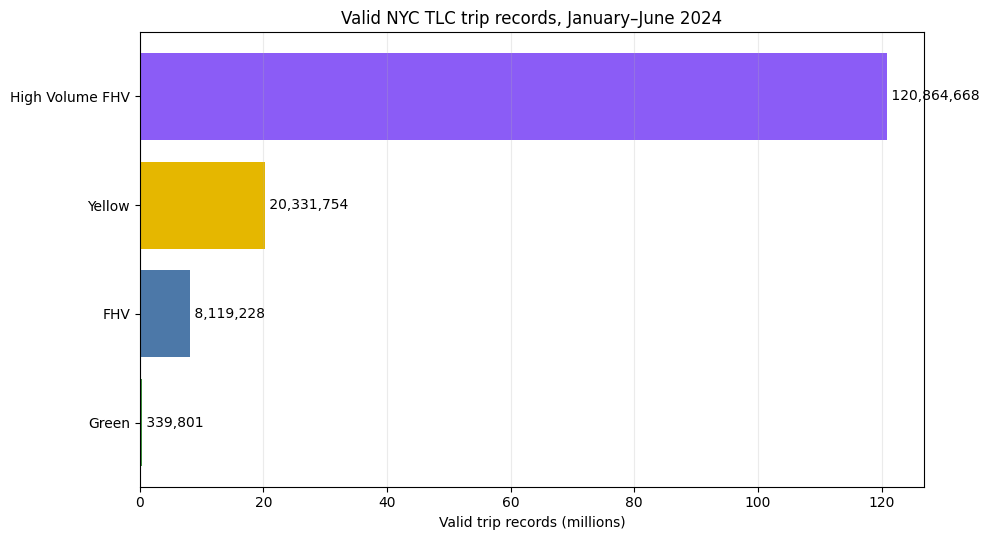

  <!-- แสดงคำตอบที่คำนวณได้เป็น Markdown -->
### Final answer

**High Volume FHV** was the most used taxi type in the first half of 2024, with **120,864,668 valid trip records**. It represented **80.76%** of all valid records and was ahead of second place by **100,532,914 records**.

**Meaning:** ผลนี้วัดจำนวน trip records ไม่ใช่จำนวนผู้โดยสาร รายได้ หรือระยะทางรวม  
**Cleaning sensitivity:** ผู้ชนะไม่เปลี่ยนเมื่อเปรียบเทียบ raw กับ valid records  
**Confidence:** สามารถตรวจย้อนกลับถึง manifest, file-level audit และกฎ valid ที่ใช้ แต่ยังขึ้นกับความถูกต้องของข้อมูลที่ TLC ได้รับจากผู้ให้บริการ


In [ ]:
# เรียงข้อมูลตามจำนวน Valid records จากน้อยไปมากสำหรับสร้างกราฟแนวนอน
plot_data = type_summary.sort_values('valid_count')

# กำหนดสีสำหรับ Taxi แต่ละประเภทให้ใช้สีเดียวกันอย่างสม่ำเสมอ
colors = {
    'Yellow': '#e5b700',  # กำหนดสีของ Yellow Taxi
    'Green': '#3a923a',  # กำหนดสีของ Green Taxi
    'FHV': '#4c78a8',  # กำหนดสีของ FHV
    'High Volume FHV': '#8b5cf6',  # กำหนดสีของ High Volume FHV
}

plt.figure(figsize=(10, 5.5))  # กำหนดขนาดของพื้นที่สำหรับแสดงกราฟ

# สร้างกราฟแท่งแนวนอน
bars = plt.barh(
    plot_data['taxi_type'],  # กำหนดประเภท Taxi บนแกนตั้ง
    plot_data['valid_count'] / 1_000_000,  # แปลงจำนวน Valid records เป็นหน่วยล้านสำหรับแกนนอน
    color=[colors[name] for name in plot_data['taxi_type']],  # กำหนดสีของแท่งกราฟตามประเภท Taxi
)

plt.title('Valid NYC TLC trip records, January–June 2024')  # กำหนดชื่อกราฟและช่วงเวลาของข้อมูล
plt.xlabel('Valid trip records (millions)')  # กำหนดชื่อแกนนอนและระบุหน่วยเป็นล้าน records
plt.grid(axis='x', alpha=0.25)  # เพิ่มเส้น Grid บนแกนนอนเพื่อช่วยให้อ่านค่าได้ง่ายขึ้น

# วนลูปเพื่อแสดงจำนวน Valid records ของแต่ละแท่ง
for bar, count in zip(bars, plot_data['valid_count']):
    plt.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f' {int(count):,}', va='center')  # แสดงจำนวนข้อมูลจริงไว้ที่ปลายแท่งกราฟ

plt.tight_layout()  # ปรับระยะขององค์ประกอบในกราฟเพื่อป้องกันข้อความถูกตัด
plt.show()  # แสดงกราฟเป็นผลลัพธ์ของ Cell

winner_count = int(valid_max)  # เก็บจำนวน Valid records สูงสุดในรูปแบบจำนวนเต็ม
winner_rows = type_summary[type_summary['valid_count'] == valid_max]  # เลือกข้อมูลของ Taxi ที่มีจำนวน Valid records สูงสุด

# ทำงานเมื่อมี Taxi ที่ได้อันดับหนึ่งเพียงประเภทเดียว
if len(valid_winners) == 1:
    winner = valid_winners[0]  # ดึงชื่อ Taxi ที่มีจำนวน Valid records สูงสุด
    winner_share = float(winner_rows.iloc[0]['valid_share_pct'])  # ดึงเปอร์เซ็นต์สัดส่วน Valid records ของผู้ชนะ
    lower_counts = type_summary.loc[type_summary['valid_count'] < valid_max, 'valid_count']  # เลือกจำนวน Valid records ของประเภทที่ต่ำกว่าอันดับหนึ่ง
    margin = int(valid_max - lower_counts.max())  # คำนวณส่วนต่างของจำนวน Valid records ระหว่างอันดับหนึ่งและอันดับสอง

    # สร้างข้อความสรุปผลเมื่อมีผู้ชนะเพียงประเภทเดียว
    answer = (
        f'**{winner}** was the most used taxi type in the first half of 2024, '
        f'with **{winner_count:,} valid trip records**. '
        f'It represented **{winner_share:.2f}%** of all valid records and was ahead of second place by **{margin:,} records**.'
    )
else:  # ทำงานเมื่อมี Taxi หลายประเภทที่มีจำนวน Valid records สูงสุดเท่ากัน
    answer = f"The result was a tie between **{', '.join(valid_winners)}**, with **{winner_count:,} valid records** each."  # สร้างข้อความสรุปผลกรณีมีอันดับหนึ่งร่วมกัน

display(Markdown(f'''  <!-- แสดงข้อความสรุปผลในรูปแบบ Markdown -->
### Final answer

{answer}

**Meaning:** ผลนี้วัดจำนวน trip records ไม่ใช่จำนวนผู้โดยสาร รายได้ หรือระยะทางรวม
**Cleaning sensitivity:** ผู้ชนะ{'เปลี่ยน' if winner_changed else 'ไม่เปลี่ยน'}เมื่อเปรียบเทียบ raw กับ valid records
**Confidence:** สามารถตรวจย้อนกลับถึง manifest, file-level audit และกฎ valid ที่ใช้ แต่ยังขึ้นกับความถูกต้องของข้อมูลที่ TLC ได้รับจากผู้ให้บริการ
'''))

### ผลลัพธ์ที่ได้

กราฟแสดงให้เห็นว่า High Volume FHV มีจำนวน valid records สูงกว่าประเภทอื่นอย่างชัดเจน โดยมีทั้งหมด 120,864,668 records คิดเป็น 80.76% ของ valid records ทั้งหมด และมากกว่า Yellow ซึ่งเป็นอันดับสองอยู่ 100,532,914 records

### ผลลัพธ์นี้หมายความว่าอย่างไร

จากตัวชี้วัดที่ใช้ในงานนี้ สรุปได้ว่า High Volume FHV เป็นประเภทที่มีจำนวน valid trip records มากที่สุดในช่วงเดือนมกราคมถึงมิถุนายน 2024 และด้วยส่วนต่างจากอันดับสองที่ค่อนข้างมาก ข้อสรุปนี้จึงไม่เปลี่ยนแปลงจากการคัดกรองข้อมูลที่ไม่ผ่านกฎด้านเวลาเพียงเล็กน้อย

ซึ่งอย่างไรก็ตาม ผลลัพธ์นี้ควรตีความว่าเป็นจำนวนระเบียนการเดินทางเท่านั้น ไม่ใช่จำนวนผู้โดยสารที่ไม่ซ้ำ รายได้รวม หรือหลักฐานว่าพฤติกรรมของผู้บริโภคเปลี่ยนจากการใช้ Taxi ประเภทหนึ่งไปสู่อีกประเภทหนึ่ง


## ขั้นตอนที่ 10: สรุปความสามารถในการรันซ้ำและตรวจสอบย้อนกลับ

สรุปกระบวนการทั้งหมดในรูปแบบ Data -> Metric -> Method -> Result -> Confidence พร้อมตรวจสอบสถานะ Quality Check อีกครั้งก่อนยืนยันผล หากทุกขั้นตอนผ่านจะแสดงสถานะ COMPLETE เพื่อยืนยันว่าการประมวลผลเสร็จสมบูรณ์ หากไม่พบสถานะนี้ ไม่ควรนำผลลัพธ์ไปใช้หรือส่งงาน


In [ ]:
# ตรวจสอบสถานะ Quality Check อีกครั้งก่อนสรุปผลการทำงาน
if not all_checks_passed:
    raise RuntimeError('INCOMPLETE')  # หยุดการทำงานหากข้อมูลไม่ผ่านการตรวจสอบ เพื่อไม่ให้แสดงสถานะ COMPLETE

print(f'Data: {len(manifest)} files, 4 taxi types, 6 months')  # สรุปจำนวนไฟล์ ประเภท Taxi และช่วงเดือนของข้อมูลที่ใช้
print('Metric: valid trip-record count')  # ระบุตัวชี้วัดที่ใช้ในการวิเคราะห์
print('Method: download, schema check, file-level audit, integration, ranking')  # สรุปขั้นตอนหลักที่ใช้ในการเตรียม ตรวจสอบ และวิเคราะห์ข้อมูล
print(f"Result: {', '.join(valid_winners)}")  # แสดงประเภท Taxi ที่มีจำนวน Valid trip records สูงสุด
print('Status: COMPLETE')  # ยืนยันว่าการประมวลผลและการตรวจสอบทั้งหมดเสร็จสมบูรณ์

print('บันทึกหรือดาวน์โหลด Notebook พร้อม outputs ก่อนส่งงาน')  # แจ้งเตือนให้บันทึก Notebook พร้อมผลลัพธ์ก่อนส่งงาน

Data: 24 files, 4 taxi types, 6 months
Metric: valid trip-record count
Method: download, schema check, file-level audit, integration, ranking
Result: High Volume FHV
Status: COMPLETE
บันทึกหรือดาวน์โหลด Notebook พร้อม outputs ก่อนส่งงาน


### ผลลัพธ์ที่ได้

Notebook สรุปว่าการวิเคราะห์ใช้ข้อมูลครบทั้งหมด 24 ไฟล์ ครอบคลุม Taxi 4 ประเภทในช่วงเวลา 6 เดือน โดยใช้จำนวน valid trip records เป็นตัวชี้วัดหลัก และได้ High Volume FHV เป็นประเภทที่มีจำนวนการใช้งานสูงสุด ทั้งนี้สถานะสุดท้ายของการประมวลผลแสดงเป็น COMPLETE

### ผลลัพธ์นี้หมายความว่าอย่างไร

สถานะ COMPLETE ยืนยันว่าการรันครั้งนี้ผ่านเงื่อนไขตรวจสอบอัตโนมัติที่กำหนดไว้ทั้งหมดก่อนแสดงผลลัพธ์สุดท้าย ทำให้สามารถตรวจสอบย้อนกลับจากคำตอบไปยังขั้นตอนการจัดอันดับ ตาราง Audit, Schema Check, Manifest และไฟล์ข้อมูลต้นทางได้อย่างเป็นลำดับ อย่างไรก็ตาม ก่อนส่งงานควรบันทึกหรือดาวน์โหลด Notebook โดยเก็บผลลัพธ์จากการรันครั้งนี้ไว้ครบถ้วน เพื่อให้สามารถตรวจสอบและทำซ้ำได้ภายหลัง


## Data Lifecycle ของงานที่ทำจริง

**ข้อมูลการเดินทาง -> เผยแพร่โดย NYC TLC -> Manifest -> ดาวน์โหลด -> จัดเก็บชั่วคราว -> ตรวจสอบ -> ทำความสะอาดและแปลง -> บูรณาการ -> วิเคราะห์และนำเสนอผล**

1. **การเกิดและแหล่งที่มาของข้อมูล:** ผู้ให้บริการบันทึกข้อมูลการเดินทางในรูปแบบ Trip Record และส่งข้อมูลให้ NYC TLC จากนั้น NYC TLC จึงเผยแพร่ข้อมูลในรูปแบบไฟล์ Parquet แยกตามประเภทและเดือน
2. **การกำหนดขอบเขตข้อมูล:** สร้าง Manifest เพื่อกำหนด Taxi ทั้ง 4 ประเภท ช่วงเดือนมกราคมถึงมิถุนายน 2024 รวมถึงชื่อไฟล์ URL และชื่อคอลัมน์ที่จำเป็น โดยมีข้อมูลทั้งหมด 24 ไฟล์
3. **การนำเข้าข้อมูล:** Notebook ดาวน์โหลดไฟล์ตาม URL ที่กำหนดไว้ใน Manifest และใช้ไฟล์เดิมหากมีอยู่แล้วใน Colab เพื่อลดการดาวน์โหลดซ้ำ
4. **การจัดเก็บข้อมูลดิบ:** ไฟล์ Parquet ถูกจัดเก็บไว้ชั่วคราวใน content/nyc_taxi_data ของ Colab และระหว่างการดาวน์โหลดจะใช้ไฟล์นามสกุล .part เพื่อป้องกันการนำไฟล์ที่ยังดาวน์โหลดไม่สมบูรณ์ไปใช้งาน
5. **การตรวจสอบคุณภาพ:** ตรวจสอบความครบถ้วนของไฟล์ Schema จำนวนข้อมูล และความสมเหตุสมผลของเวลาในแต่ละ record พร้อมตรวจสอบว่าจำนวน raw records สอดคล้องกับผลรวมของ valid และ invalid records
6. **การทำความสะอาดและแปลงข้อมูล:** แยกข้อมูลที่ผ่านและไม่ผ่านกฎด้านเวลา จากนั้นแปลงผลการตรวจสอบของแต่ละไฟล์ให้อยู่ในรูปแบบ Audit Table ที่มีโครงสร้างเดียวกัน
7. **การบูรณาการข้อมูล:** รวมผลจากทั้ง 24 ไฟล์เพื่อสร้างตารางสรุปรายเดือนและรายประเภท ก่อนคำนวณสัดส่วน อัตราข้อมูลที่ไม่ผ่าน และอันดับของ Taxi แต่ละประเภท
8. **การวิเคราะห์และนำเสนอ:** เปรียบเทียบอันดับจาก raw records และ valid records สร้างกราฟสรุปผล และระบุว่า High Volume FHV มีจำนวน valid trip records มากที่สุดในช่วงเวลาที่ศึกษา
9. **การจัดเก็บผลลัพธ์:** เก็บตารางสรุป กราฟ ผลการตรวจสอบคุณภาพ และคำตอบสุดท้ายไว้ภายใน Notebook พร้อม Outputs เพื่อให้สามารถตรวจสอบย้อนกลับและนำไปรันซ้ำได้ในภายหลัง

## การตัดสินใจสำคัญอย่างน้อย 2 ข้อ พร้อมเหตุผล

### การตัดสินใจข้อที่ 1: ใช้จำนวน valid trip records เป็นตัวชี้วัด

เลือกตัวชี้วัดนี้เพราะข้อมูลทั้ง 4 ประเภทมีหนึ่งแถวแทน trip record และมีเวลา pickup/dropoff ที่ใช้กฎร่วมกันได้ หากใช้จำนวนผู้โดยสาร ระยะทาง หรือค่าโดยสาร จะเปรียบเทียบ FHV ได้ไม่ครบเพราะไม่มีคอลัมน์เหล่านี้เหมือนประเภทอื่น ข้อจำกัดคือหนึ่ง record ไม่ได้หมายถึงผู้โดยสารหนึ่งคน

### การตัดสินใจข้อที่ 2: ใช้ DuckDB ประมวลผล Parquet โดยตรง

ข้อมูล High Volume FHV มีขนาดใหญ่และไฟล์ทั้งหมดรวมประมาณ 3.12 GB หากโหลดทุกแถวเข้า Pandas พร้อมกันอาจใช้ RAM เกินขนาดของ Colab จึงให้ DuckDB อ่านเฉพาะคอลัมน์ที่จำเป็นและส่งเฉพาะตารางสรุปขนาดเล็กให้ Pandas วิธีนี้ใช้หน่วยความจำน้อยลง แต่ต้องเขียน SQL และจัดการชื่อคอลัมน์ให้ถูกต้อง

### การตัดสินใจข้อที่ 3: ใช้กฎทำความสะอาดแบบระมัดระวัง

ตัดออกจาก metric เฉพาะ record ที่ผิดกฎเวลาซึ่งตรวจได้เหมือนกันทุกประเภท ส่วนระยะทางเป็นศูนย์ ค่าโดยสารติดลบ และ duplicate candidates ยังไม่ถูกลบ เพราะอาจเกิดจากบริบทของบริการและไม่มี trip ID สำหรับยืนยัน วิธีนี้ลดความเสี่ยงจากการลบข้อมูลจริง แต่ record ที่น่าสงสัยบางส่วนอาจยังถูกนับอยู่

### การตัดสินใจข้อที่ 4: ไม่ตอบคำถามเมื่อข้อมูลไม่ครบ

กำหนดให้ Notebook แสดงสถานะ INCOMPLETE และหยุดทำงานเมื่อ Manifest, ไฟล์, Schema หรือ Audit ไม่ครบ เพราะการขาดเพียงบางเดือนหรือบางประเภทอาจทำให้การเปรียบเทียบไม่ยุติธรรม จะแสดงคำตอบสุดท้ายเมื่อ Quality Check ทุกข้อผ่านเท่านั้น

## สิ่งที่เรียนรู้และข้อจำกัดของวิธีที่ใช้

### สิ่งที่เรียนรู้

งานนี้ทำให้เห็นว่าควรนิยามคำว่า **most used** ให้ชัดก่อนเริ่มเขียน code เพราะคำเดียวกันอาจหมายถึงจำนวนเที่ยว จำนวนผู้โดยสาร รายได้ หรือระยะทางก็ได้ นอกจากนี้ แม้ไฟล์ทั้งหมดเป็น Parquet แต่ชื่อคอลัมน์และข้อมูลที่มีในแต่ละประเภทไม่เหมือนกัน จึงต้องตรวจ Schema และสร้าง Manifest ก่อนรวมผล

อีกเรื่องที่ได้เรียนรู้คือเครื่องมือควรเหมาะกับขนาดงาน DuckDB เหมาะกับการอ่านและ aggregate Parquet ขนาดใหญ่ ส่วน Pandas เหมาะกับตารางสรุปและกราฟ การทำ Audit และเปรียบเทียบ raw กับ valid records ทำให้เห็นว่ามีข้อมูลไม่ผ่านกฎเวลา 345 records แม้อันดับและผู้ชนะจะไม่เปลี่ยนก็ตาม

### ข้อจำกัดของวิธีที่ใช้

- จำนวน trip records ไม่ใช่จำนวนผู้โดยสารที่ไม่ซ้ำกัน จึงตอบได้เฉพาะประเภทที่มี records มากที่สุดตาม metric นี้
- ข้อมูลมาจากผู้ให้บริการผ่าน NYC TLC ความน่าเชื่อถือของผลจึงยังขึ้นกับความถูกต้องของข้อมูลต้นทาง
- Taxi แต่ละประเภทมีรูปแบบบริการต่างกัน การเปรียบเทียบจึงทำได้ในระดับ record ที่ผ่านกฎร่วมกันเท่านั้น
- ไม่มี trip ID กลาง จึงไม่สามารถยืนยันและลบข้อมูลซ้ำได้ การตรวจ duplicate candidates ใช้เพียง 10,000 แถวแรกต่อไฟล์และเป็น diagnostic เท่านั้น
- กฎทำความสะอาดตรวจเฉพาะความสมเหตุสมผลของเวลา จึงอาจยังเก็บ record ที่มีระยะทางเป็นศูนย์ ค่าโดยสารติดลบ หรือค่าที่น่าสงสัยอื่นไว้
- ผลลัพธ์ครอบคลุมเฉพาะเดือนมกราคมถึงมิถุนายน 2024 จึงไม่ควรนำไปสรุปแนวโน้มระยะยาวหรือการเปลี่ยนพฤติกรรมของผู้โดยสาร
- การรันครั้งแรกต้องใช้เครือข่าย พื้นที่ประมาณ 3.12 GB และเวลาสำหรับดาวน์โหลดกับประมวลผล ไฟล์ใน `/content` จะหายเมื่อ Colab session สิ้นสุดหากไม่ได้ย้ายไปจัดเก็บที่อื่น